# PF8 00buildings: how good is Santiago's building data?

PF8 is a 3D city scene of Santiago, Chile: TerrainLayer ground with the Andes behind, extruded buildings, and winter smog trapped under the inversion.

This notebook checks the buildings before anything is built on them. It reads every building and building part inside a box over central Santiago (Santiago Centro, Providencia, Las Condes) from the Geofabrik Chile extract of OpenStreetMap, and answers three questions:

1. How many buildings have a real height or a floor count?
2. How many `building:part` pieces are there (these give stepped towers and setbacks)?
3. Are the tall landmark towers mapped in detail?

Output: `data/buildings_santiago.parquet` (GeoParquet, one row per building or part) for the next notebooks.

## 0. Settings

In [1]:
from pathlib import Path

DATA_DIR = Path("data")  # <- where downloads and outputs go
PBF_URL = "https://download.geofabrik.de/south-america/chile-latest.osm.pbf"  # <- Geofabrik Chile extract
PBF_FILE = DATA_DIR / "chile-latest.osm.pbf"
OUT_FILE = DATA_DIR / "buildings_santiago.parquet"

# Study box: west, south, east, north (degrees). Covers Santiago Centro to Las Condes.
BBOX = (-70.70, -33.47, -70.53, -33.39)  # <- widen or shrink the study area

LEVEL_HEIGHT_M = 3.0  # <- metres per floor when only building:levels is known
TOP_N = 25  # <- how many of the tallest buildings to list

DATA_DIR.mkdir(exist_ok=True)

## 1. Download the Chile extract (once)

Skipped if the file is already there. A few hundred MB, so this can take a few minutes.

In [2]:
import urllib.request
import time

if PBF_FILE.exists():
    print(f"Already have {PBF_FILE} ({PBF_FILE.stat().st_size / 1e6:.0f} MB)")
else:
    t0 = time.time()
    print(f"Downloading {PBF_URL} ...")
    req = urllib.request.Request(PBF_URL, headers={"User-Agent": "PF8 portfolio notebook (likrentai)"})
    tmp = PBF_FILE.with_suffix(".part")
    with urllib.request.urlopen(req) as r, open(tmp, "wb") as f:
        while True:
            chunk = r.read(1 << 20)
            if not chunk:
                break
            f.write(chunk)
    tmp.rename(PBF_FILE)
    print(f"Done: {PBF_FILE.stat().st_size / 1e6:.0f} MB in {time.time() - t0:.0f} s")

Done: 352 MB in 39 s


## 2. Read buildings and building parts inside the box

pyosmium assembles every closed way and multipolygon relation into an area. We keep only areas tagged `building` or `building:part` whose shape falls inside the study box, with the tags that matter for 3D:

- `height`, `min_height` (metres)
- `building:levels`, `building:min_level` (floor counts)
- `roof:shape`, `roof:height`, `name`

In [3]:
import osmium
import shapely.wkb
from shapely.geometry import box

study_box = box(*BBOX)
wkb_factory = osmium.geom.WKBFactory()
KEEP_TAGS = ["building", "building:part", "height", "min_height", "building:levels", "building:min_level", "roof:shape", "roof:height", "roof:levels", "name"]


class BuildingHandler(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.errors = 0

    def area(self, a):
        tags = a.tags
        if "building" not in tags and "building:part" not in tags:
            return
        try:
            geom = shapely.wkb.loads(wkb_factory.create_multipolygon(a), hex=True)
        except Exception:
            self.errors += 1
            return
        if not study_box.intersects(geom):
            return
        row = {k: tags.get(k) for k in KEEP_TAGS}
        row["osm_type"] = "way" if a.from_way() else "relation"
        row["osm_id"] = a.orig_id()
        row["geometry"] = geom
        self.rows.append(row)


t0 = time.time()
handler = BuildingHandler()
handler.apply_file(str(PBF_FILE), locations=True, idx="flex_mem")
print(f"Read {len(handler.rows):,} buildings and parts in the box in {time.time() - t0:.0f} s ({handler.errors} broken shapes skipped)")

Read 71,874 buildings and parts in the box in 47 s (1 broken shapes skipped)


## 3. Tidy heights

Heights in OSM are text, sometimes with units (`"45 m"`, `"120m"`, `"45,5"`). Each row gets one `height_m` and a note of where it came from:

- `height`: a measured or mapped height in metres
- `levels`: estimated from `building:levels` times the floor height in Section 0
- `none`: no height information (will need an estimate later)

In [4]:
import re
import pandas as pd
import geopandas as gpd

gdf = gpd.GeoDataFrame(handler.rows, geometry="geometry", crs="EPSG:4326")


def to_number(text):
    if text is None:
        return None
    s = str(text).strip().lower().replace(",", ".")
    m = re.match(r"^([0-9]*\.?[0-9]+)", s)
    if m is None:
        return None
    value = float(m.group(1))
    if "ft" in s or "'" in s:
        value = value * 0.3048
    return value


gdf["height_tag_m"] = gdf["height"].map(to_number).astype("float64")
gdf["min_height_tag_m"] = gdf["min_height"].map(to_number).astype("float64")
gdf["levels"] = gdf["building:levels"].map(to_number).astype("float64")
gdf["min_level"] = gdf["building:min_level"].map(to_number).astype("float64")

gdf["height_m"] = gdf["height_tag_m"].fillna(gdf["levels"] * LEVEL_HEIGHT_M)
gdf["height_source"] = "none"
gdf.loc[gdf["levels"].notna(), "height_source"] = "levels"
gdf.loc[gdf["height_tag_m"].notna(), "height_source"] = "height"
gdf["min_height_m"] = gdf["min_height_tag_m"].fillna(gdf["min_level"] * LEVEL_HEIGHT_M).fillna(0.0)

gdf["kind"] = "building"
gdf.loc[gdf["building:part"].notna() & gdf["building"].isna(), "kind"] = "part"
gdf.loc[gdf["building:part"].notna() & gdf["building"].notna(), "kind"] = "building and part"

print(gdf[["kind", "height_source"]].value_counts().sort_index().to_string())

kind               height_source
building           height             497
                   levels           14240
                   none             56613
building and part  height              10
                   none                 2
part               height             237
                   levels             156
                   none               119


## 4. Coverage summary: question 1 and 2

In [5]:
gdf_m = gdf.to_crs("EPSG:32719")  # UTM 19S, metres
gdf["area_m2"] = gdf_m.area

summary = gdf.groupby("kind").agg(count=("osm_id", "size"), with_height_tag=("height_tag_m", lambda s: s.notna().sum()), with_levels=("levels", lambda s: s.notna().sum()), no_height=("height_source", lambda s: (s == "none").sum()), footprint_km2=("area_m2", lambda s: s.sum() / 1e6))
summary["share_with_any_height"] = 1 - summary["no_height"] / summary["count"]
print(summary.round(3).to_string())

n_buildings = (gdf["kind"] != "part").sum()
n_parts = (gdf["kind"] != "building").sum()
print()
print(f"Buildings: {n_buildings:,}   Building parts: {n_parts:,}")
print(f"Share of building footprint area with any height: {gdf.loc[gdf['height_source'] != 'none', 'area_m2'].sum() / gdf['area_m2'].sum():.1%}")

                   count  with_height_tag  with_levels  no_height  footprint_km2  share_with_any_height
kind                                                                                                   
building           71350              497        14576      56613         20.539                  0.207
building and part     12               10           10          2          0.005                  0.833
part                 512              237          302        119          0.253                  0.768

Buildings: 71,362   Building parts: 524
Share of building footprint area with any height: 24.5%


## 5. The tallest buildings: question 3

If the landmark towers (Gran Torre Costanera, Titanium La Portada and others) appear here with sensible heights, and some have parts, the detailed look is possible at least for the skyline.

In [6]:
tallest = gdf.sort_values("height_m", ascending=False).head(TOP_N)
tallest_view = tallest[["name", "kind", "height_m", "min_height_m", "height_source", "levels", "roof:shape", "osm_type", "osm_id"]].copy()
tallest_view["height_m"] = tallest_view["height_m"].round(1)
print(tallest_view.to_string(index=False))

                         name     kind  height_m  min_height_m height_source  levels roof:shape osm_type     osm_id
                          NaN     part     300.0           0.0        height     NaN   skillion      way  553633727
                          NaN     part     300.0           0.0        height     NaN   skillion      way  553633726
                          NaN     part     300.0           0.0        height     NaN   skillion      way  553633729
         Gran Torre Costanera building     300.0           0.0        height    64.0       flat      way 1179710949
                          NaN     part     300.0           0.0        height     NaN   skillion      way  553634596
                          NaN     part     300.0           0.0        height     NaN   skillion      way  553633731
                          NaN     part     300.0           0.0        height     NaN   skillion      way  553633721
                          NaN     part     300.0           0.0        he

## 6. Map: where the heights are

Grey: no height. Colour: height in metres. Gaps in colour show where the 3D scene would need estimated heights.

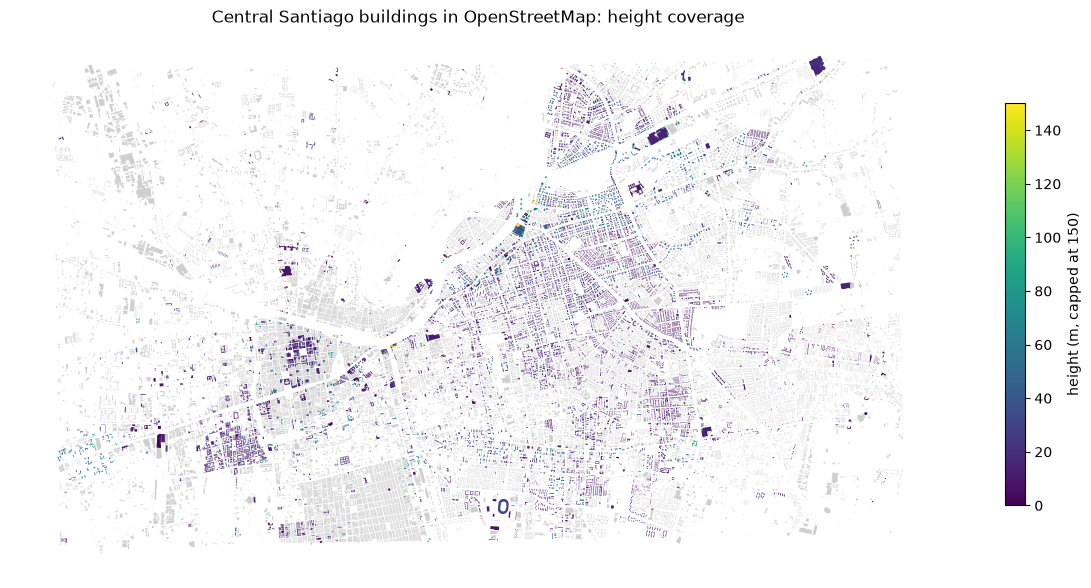

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 7))
plain = gdf_m[gdf["height_source"] == "none"]
known = gdf_m[gdf["height_source"] != "none"].copy()
known["height_m"] = gdf.loc[known.index, "height_m"].clip(upper=150)
plain.plot(ax=ax, color="#cfcfcf", linewidth=0)
known.plot(ax=ax, column="height_m", cmap="viridis", linewidth=0, legend=True, legend_kwds={"label": "height (m, capped at 150)", "shrink": 0.6})
ax.set_title("Central Santiago buildings in OpenStreetMap: height coverage")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 7. Save

In [8]:
keep = ["osm_type", "osm_id", "kind", "name", "building", "building:part", "height_m", "min_height_m", "height_source", "levels", "roof:shape", "roof:height", "area_m2", "geometry"]
gdf[keep].to_parquet(OUT_FILE)
print(f"Saved {len(gdf):,} rows to {OUT_FILE} ({OUT_FILE.stat().st_size / 1e6:.1f} MB)")

Saved 71,874 rows to data\buildings_santiago.parquet (8.5 MB)


___
**END**